In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [6]:
datasets_colors = {'BBBC039':'#FFC0CB',
                   'mnfinder':'#80ED99',
                   'mnDINO_data_01':'#192A56',
                   'mnDINO_data_02':'#00A3FF'}

objects_color = {'Nuc':'#00A3FF',
                 'MN':'#A68CFF'}

# plt.rcParams.update({'font.size':12})

# sns.set(font_scale=1.5, style='white')

In [7]:
scores_path = '/hdd/jcaicedo/projects/micronuclei_detection/Train_and_Eval/mndino_data/figures/dinov3_scores.csv'
scores = pd.read_csv(scores_path)
scores

,Datasets,Precision,Recall,Setting
0,BBBC039,0.63,0.55,"LR: 0.001, Batch: 8"
1,Pilot_Screen,0.92,0.63,"LR: 0.001, Batch: 8"
2,HeLa_RPE1,0.73,0.74,"LR: 0.001, Batch: 8"
3,MNFinder Data,0.71,0.67,"LR: 0.001, Batch: 8"
4,BBBC039,0.57,0.78,"LR: 0.001, Batch: 16"
5,Pilot_Screen,0.70,0.87,"LR: 0.001, Batch: 16"
6,HeLa_RPE1,0.67,0.90,"LR: 0.001, Batch: 16"
7,MNFinder Data,0.72,0.77,"LR: 0.001, Batch: 16"
8,BBBC039,0.56,0.83,"LR: 0.001, Batch: 32"
9,Pilot_Screen,0.65,0.89,"LR: 0.001, Batch: 32"


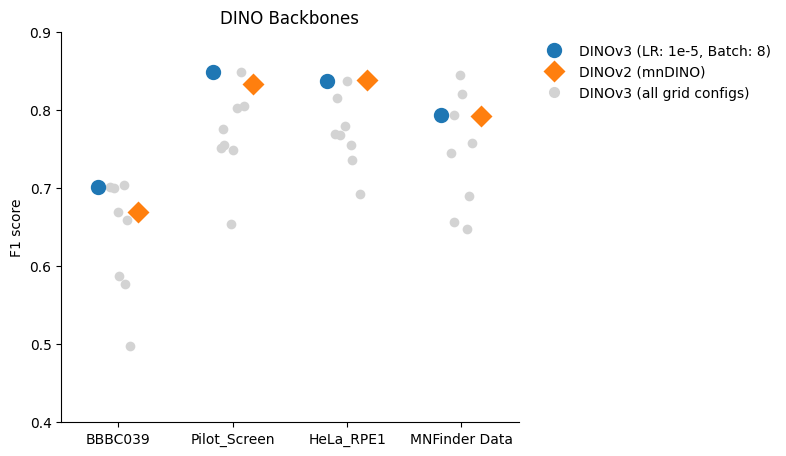

In [14]:
scores['F1'] = 2 * scores['Precision'] * scores['Recall'] / (scores['Precision'] + scores['Recall'])
v3 = scores[scores['Setting'] != 'mnDINO']

# One DINOv3 config chosen by mean F1 over all datasets (not cherry-picked per dataset)
best = v3.groupby('Setting')['F1'].mean().idxmax()
compare = scores[scores['Setting'].isin([best, 'mnDINO'])].copy()
compare['Model'] = compare['Setting'].map({'mnDINO': 'DINOv2 (mnDINO)', best: f'DINOv3 ({best})'})

order = ['BBBC039', 'Pilot_Screen', 'HeLa_RPE1', 'MNFinder Data']
plt.figure(figsize=(8, 4.5))
ax = sns.stripplot(data=v3, x='Datasets', y='F1', order=order,
                   color='lightgray', size=7, jitter=0.12, zorder=1)
sns.pointplot(data=compare, x='Datasets', y='F1', hue='Model', order=order,
              dodge=0.35, linestyle='none', markers=['o', 'D'], markersize=9, ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], marker='o', color='lightgray', linestyle='none', markersize=7))
labels.append('DINOv3 (all grid configs)')
ax.legend(handles, labels, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)

ax.set_ylabel('F1 score'); ax.set_xlabel('')
ax.set_ylim(0.4, 0.9)
sns.despine(); plt.tight_layout()
plt.title('DINO Backbones')
plt.show()